In [ ]:
# ====================================
# Import libraries
# ====================================
import torch
from torch import nn, optim
import torch.nn.functional as F
from torch.utils.data import random_split, DataLoader
import torchvision.transforms.v2 as T
from torch.utils.data import TensorDataset
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random

In [20]:
# ====================================
# Reproducibility and device
# ====================================
r_seed = 99
generator = torch.Generator()

def reset_seed(seed=r_seed):
    """Reset all seeds at once."""
    random.seed(seed) #reset python random seed
    np.random.seed(seed) #reset numpy random seed
    torch.manual_seed(seed) #reset pytorch random seed
    generator.manual_seed(seed) #reset the dataloader random seed
    if torch.cuda.is_available(): #if we use the gpu
        torch.cuda.manual_seed_all(seed)

reset_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


Using device: cpu


In [21]:
# ====================================
# Load the Clock dataset (75x75)
# ====================================
img_size = 75 #So that we can change it to 150x150 if needed
images_path = f"data/{img_size:03d}_images.npy"
labels_path = f"data/{img_size:03d}_labels.npy"

images_np = np.load(images_path)
labels_np = np.load(labels_path)

#Check out our images 
print("images:", images_np.shape, images_np.dtype, images_np.min(), images_np.max()) #18'000 images, 75x75
print("labels:", labels_np.shape, labels_np.dtype) #18'000 labels, 2 dimensions (hour, min)
print("hours:", np.unique(labels_np[:, 0])) #they go from 0 to 11
print("minutes:", labels_np[:, 1].min(), labels_np[:, 1].max()) #they go from 0 to 59

#Convert into pytorch tensors
images = torch.from_numpy(images_np).float() #turn numpy array into pytorch tensor, float
images = images.unsqueeze(1) #add channel dimension, we need format (batch_size, channels, height, width) (greyscale = 1 channel)
mean = images.mean()
std = images.std()
images = (images - mean) / std #standardize the pixels (easier for training)

labels_minutes = torch.from_numpy(labels_np[:, 0] * 60 + labels_np[:, 1]).long() #hours*60 + minutes, and turn it into pytorch tensor
print(labels_minutes.shape, labels_minutes.min(), labels_minutes.max()) #18'000 labels, 1 dimension (min). Minutes go from 0 (00:00) to 719 (11:59). 

#We are trying to predict:
#Hours: from 0 to 11.
#Minutes: from 0 to 59.
#Total minutes: sum of hours (in minutes) + minutes (12 hours*60 = 720 minutes).

images: (18000, 75, 75) uint8 16 255
labels: (18000, 2) int64
hours: [ 0  1  2  3  4  5  6  7  8  9 10 11]
minutes: 0 59
torch.Size([18000]) tensor(0) tensor(719)


In [22]:
#=====================================
# Train-Validation-Test split
# ====================================
reset_seed()

dataset = TensorDataset(images, labels_minutes)
n = len(dataset)

train_size = int(0.8 * n)
valid_size = int(0.1 * n)
test_size = n - train_size - valid_size

train_data, valid_data, test_data = random_split(
    dataset,
    [train_size, valid_size, test_size],
    generator=generator
)

batch_size = 64

train_dataloader = DataLoader(
    train_data,
    batch_size=batch_size,
    shuffle=True,
    generator=generator
)

valid_dataloader = DataLoader(
    valid_data,
    batch_size=batch_size,
    shuffle=True 
)

test_dataloader = DataLoader(
    test_data,
    batch_size=batch_size,
    shuffle=True
)

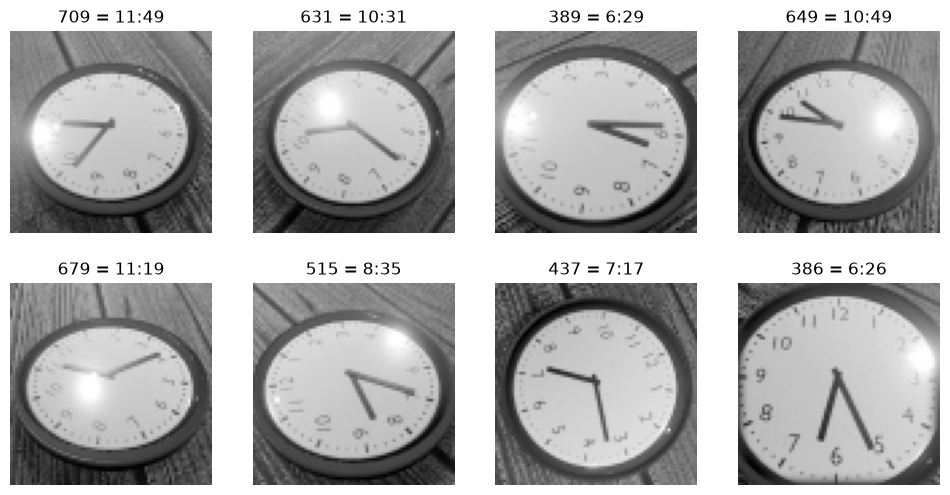

In [23]:
#=====================================
# Trying to see images
# ====================================
images_batch, labels_batch = next(iter(train_dataloader))

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, img, y in zip(axes.flat, images_batch, labels_batch):
    m = y.item() #number of minutes from midnight
    ax.imshow(img[0]*std + mean, cmap="gray")
    ax.set_title(f"{m} = {m // 60}:{m % 60:02d}")  
    ax.axis("off")
plt.show()

In [ ]:
# =====================================
# Data Agumentation
# =====================================

#The images above appear:
# - Rotated in different orientations
# - There are bright spots
# - They are slightly tilted
#We need to try to account for these differences

#train_transform = T.Compose([
#    T.RandomRotation(degrees=180),                          #rotation
#    T.RandomPerspective(distortion_scale=0.15, p=0.4),       #tilt
#    T.ColorJitter(brightness=0.3, contrast=0.3),             #soften the bright spots
#])

In [ ]:
# =====================================
# Setting up the CNN
# =====================================

class Net_4conv(nn.Module):   #Final CNN
    def __init__(self, num_classes):  #allow to provide a desired number of classes
        super().__init__()
        #Input image (1, 75, 75) (greyscale, 75x75)
        self.conv1 = nn.Conv2d(1, 6, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 3, padding=1)
        self.conv3 = nn.Conv2d(16, 32, 3, padding=1)
        self.conv4 = nn.Conv2d(32, 64, 3, padding=1)
        self.fc1 = nn.Linear(64 * 4 * 4, 120)
        self.fc2 = nn.Linear(120, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))
        x = self.pool(F.relu(self.conv4(x)))
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

In [ ]:
# ======================================================
# Defining the functions for training and evaluation
# ======================================================


#Train the model

def train_model(model, train_dataloader, optimizer, criterion, epochs, bin_size):
    
    """Train a model for a given number of epochs."""
    
    for epoch in range(epochs):
        
        model.train() 
        running_loss = 0.0
        
        for inputs, minutes in train_dataloader:
            
            #data agumentation
            #inputs = train_transform(inputs)
            
            #To use external GPU
            inputs = inputs.to(device)                    
            minutes = minutes.to(device)
            
            #convert the labels from labels in minutes (e.g., 01:30 --> 90 minutes) to labels in classes (e.g., class 3)
            labels_class = (minutes // bin_size).long() 

            #zero the parameter gradients
            optimizer.zero_grad()

            #forward + backward + optimize
            outputs = model(inputs) #predictions
            loss = criterion(outputs, labels_class) #compute loss 
            loss.backward() #compute gradients
            optimizer.step() #optimize weights

            #compute running loss
            running_loss += loss.item()
        print(
            f"Epoch {epoch + 1}/{epochs}: "
            f"- Loss = {running_loss/len(train_dataloader):.4f}"
        )

#Validate the model

def evaluate_model(model, dataloader, bin_size):

    """Evaluate a model using the average circular time error."""

    model.eval()

    total_error = 0
    total = 0

    with torch.no_grad():
        for inputs, minutes in dataloader:
            
            #To use external GPU
            inputs = inputs.to(device)                    
            minutes = minutes.to(device)
            
            #Get predictions and classes
            outputs = model(inputs) #predictions (in classes!!!)
            predictions = outputs.argmax(dim=1) #assign to the class with the highest score

            #Convert predicted classes back into total minutes
            predicted_minutes = predictions * bin_size + (bin_size - 1) / 2 #midpoint to represent the class

            #Calculate absolute difference and the circular difference
            difference = torch.abs(predicted_minutes - minutes)
            circular_difference = torch.minimum(difference, 720 - difference)

            #Compute the errors
            total_error += circular_difference.sum().item()
            total += minutes.size(0)

    common_sense_error = total_error / total

    return common_sense_error

In [ ]:
# ======================================================
# Sanity check (baseline reference) - Bins of 30 minutes, 20 epochs
# ======================================================

#To check that the overall structure works, before moving on to parameter optimization
epochs = 20 
bin_size = 30

#Calculate the number of classes (with 30 minutes bins)
num_classes = 720 // bin_size

#Model
model = Net_4conv(num_classes).to(device)

#Loss function
criterion = nn.CrossEntropyLoss()

#Optimizer
optimizer = optim.Adam(model.parameters(), lr=0.001)

#Train the model
train_model(
    model,
    train_dataloader,
    optimizer,
    criterion,
    epochs,
    bin_size
)

#Evaluate on validation data
valid_error = evaluate_model(
    model,
    valid_dataloader,
    bin_size
)

print(f"Average common-sense error: {valid_error:.2f} minutes")

In [ ]:
# =====================================
# Experiment with different bin sizes
# =====================================

bin_sizes = [30, 15, 5, 1] #30 minutes bins, 15 minutes bins, 5 minutes bins, 1 minute bins
epochs_list = [20, 30, 50]
learning_rate = 0.001
results, models = [], {}

for bin_size in bin_sizes:

    #Calculate number of classes
    num_classes = 720 // bin_size
    
    for epochs in epochs_list:

        print(f"\nExperiment: {bin_size}-minute bins ({num_classes} classes), {epochs} epochs")

        #New seed for every experiment
        reset_seed()

        #Create a new CNN
        model = Net_4conv(num_classes).to(device)

        #Loss function
        criterion = nn.CrossEntropyLoss()

        #Optimizer
        optimizer = optim.Adam(model.parameters(), lr=learning_rate)

        #Train model
        train_model(
            model,
            train_dataloader,
            optimizer,
            criterion,
            epochs,
            bin_size
        )

        #Evaluate model
        valid_error = evaluate_model(
            model,
            valid_dataloader,
            bin_size
        )

        models[bin_size] = model

        # Store results
        results.append({
            "Bin size": bin_size,
            "Number of classes": num_classes,
            "Number of epochs": epochs,
            "Common-sense error (min)": valid_error
        })

        print(f"\nCommon-sense error: {valid_error:.2f} minutes")

results_df = pd.DataFrame(results)
print(results_df)



Experiment: 30-minute bins (24 classes), 20 epochs
Epoch 1/20: - Loss = 3.1806
Epoch 2/20: - Loss = 3.1787
Epoch 3/20: - Loss = 3.1788
Epoch 4/20: - Loss = 3.1784
Epoch 5/20: - Loss = 3.1779
Epoch 6/20: - Loss = 3.0717
Epoch 7/20: - Loss = 2.4467
Epoch 8/20: - Loss = 2.0669
Epoch 9/20: - Loss = 1.9029
Epoch 10/20: - Loss = 1.8000
Epoch 11/20: - Loss = 1.6905
Epoch 12/20: - Loss = 1.5959
Epoch 13/20: - Loss = 1.5086
Epoch 14/20: - Loss = 1.4230
Epoch 15/20: - Loss = 1.3488
Epoch 16/20: - Loss = 1.2688
Epoch 17/20: - Loss = 1.2152
Epoch 18/20: - Loss = 1.1414
Epoch 19/20: - Loss = 1.0881
Epoch 20/20: - Loss = 1.0354

Common-sense error: 61.78 minutes

Experiment: 30-minute bins (24 classes), 30 epochs
Epoch 1/30: - Loss = 3.1806
Epoch 2/30: - Loss = 3.1787
Epoch 3/30: - Loss = 3.1788
Epoch 4/30: - Loss = 3.1784
Epoch 5/30: - Loss = 3.1779
Epoch 6/30: - Loss = 3.0717
Epoch 7/30: - Loss = 2.4467
Epoch 8/30: - Loss = 2.0669
Epoch 9/30: - Loss = 1.9029
Epoch 10/30: - Loss = 1.8000
Epoch 11/

In [ ]:
# =====================================
# Test set - With Best Parameters
# =====================================

#Best parameters
best_row = results_df.loc[results_df["Common-sense error (min)"].idxmin()]
best_bin_size = int(best_row["Bin size"])

#Evaluate the final model on test set
test_error = evaluate_model(
    models[best_bin_size], 
    test_dataloader, 
    best_bin_size
)


print(f"Best bin size: {best_bin_size}, test common-sense error: {test_error:.2f} minutes")

In [ ]:
# =====================================
# Reconstruct the parameter optimization
# =====================================

"""
Initial approach:

To build the CNN for this task we took as baseline the task1_CCN. We knew that it wouldn't be enough, but at least we could see
how it behaved and improve it from there. With those settings some problems immediately came up:
- The loss started flat for about 5 epochs before it started dropping --> the training is unstable and insufficient
- Increasing the number of epochs helped a lot for larger bin sizes (30, 15) less for 5 minutes bins, and not at all for 1 minute 
bins --> the model was not learning
- The model was underfitting --> Data Agumentation could have helped if the model was overfitting, but here it was doing the opposite.
We needed a bigger model, so a more complex CNN. 

This was a suggestion that we needed to change our CNN:
- More layers?
- Different initial weights?
- Padding?

# =====================================
First try: 
- Experiment 1: 
    bin_sizes = 30 #30 minutes bins
    epochs = 10
    learning_rate = 0.001
    
- Experiment 2:
    bin_sizes = [30, 15, 5, 1] #30 minutes bins, 15 minutes bins, 5 minutes bins, 1 minute bins
    epochs = 10
    learning_rate = 0.001

- Experiment 3:
    bin_sizes = [5, 1] #5 minutes bins, 1 minute bins are very small, might need more epochs
    epochs = 20 #try more epochs for harder classes
    learning_rate = 0.001

Results:
- The model is learning, loss diminishes --> it works
- The performance gets worse with smaller bins --> harder task when bins are very small
- The model is basically not learning with 720 classes --> larger learning rate? larger NN?
- Going from 10 to 20 epochs for 30 bins improves the model --> training for longer helps
- The loss did not reach a plateau --> we are not overfitting yet.

# =====================================
Second try: 
- Experiment 1 (keep for sanity check, but don't re-run every time)
    
- Experiment 2 (and 3 merged):
    bin_sizes = [30, 15, 5, 1] #30 minutes bins, 15 minutes bins, 5 minutes bins, 1 minute bins
    epochs_list = [20, 30, 50]
    learning_rate = 0.001

Results:
- For large bins 30 and 15, with more epochs the error diminishes exponentially ! --> epochs value should be around 30-50 (or even more)
- For small bins, even if increasing the number of epochs keeps reducing the error, we still have a very high common sense error, 
and the model doesn't learn enough --> need to change something in the structure of the network
- For bin_size = 1, more epochs make absolutely no difference --> need to change something in the structure of the network
- For the "easiest" model to train (30 minutes bins), with the largest number of epochs (50), the common-sense error is still very 
high (32.63 minutes). We need to change something in the structure of the network

"""

In [ ]:
# =====================================
# Questions
# =====================================

"""
What limitations does a direct high-cardinality classification representation exhibit?

Limitation 1:
With a higher number of classes to distinguish, the classification task becomes increasingly more complex.
We might need larger training data, longer training time, more epochs, and more neurons.
To understand this, if we look at the results from our model when bin_size = 1 minute, we realise that the loss
barely diminishes. This means that the model is not learning.  

Limitation 2:
With the Cross Entropy Loss, all wrong predictions are simply classified as incorrect, but the model
doesn't understand the difference between a prediction that is off by 1 minute and one that is off by hours.
It just classifies them both as "incorrect class". This problem gets worse when we consider the circular nature of time 
(at the boundary 719 minutes and 0 are very close), and the number of classes increases. 

Limitation 3:
Dividing time into large bins (e.g., more than 5 minutes) makes the classification task easier, but
causes severe loss of information (with 30 minutes bins, our prediction, even if it's correct, it's not very precise).

"""